In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyodbc

print("All libraries working successfully!")

All libraries working successfully!


In [2]:
server = r'EKANSH-LAPTOP\SQLEXPRESS'
database = 'Olist_Marketing_Analytics'

drivers = pyodbc.drivers()

driver = next(
    (d for d in [
        'ODBC Driver 18 for SQL Server',
        'ODBC Driver 17 for SQL Server'
    ] if d in drivers),
    None
)

if driver is None:
    raise RuntimeError("SQL Server ODBC driver 17 or 18 is required.")

connection = pyodbc.connect(
    f'DRIVER={{{driver}}};'
    f'SERVER={server};'
    f'DATABASE={database};'
    'Trusted_connection=yes;'
    'Encrypt=yes;'
    'TrustServerCertificate=yes;'
)

print("Successfully connected to SQL Server!")

Successfully connected to SQL Server!


In [3]:
cursor = connection.cursor()

cursor.execute("SELECT COUNT(*) FROM clean_marketing_leads")
total_leads = cursor.fetchone()[0]
print("Total Marketing Leads:", total_leads)

Total Marketing Leads: 8000


In [4]:
leads = pd.read_sql_query("SELECT * FROM clean_marketing_leads", connection)

deals = pd.read_sql_query("SELECT * FROM clean_closed_deals", connection)

print("Marketing Leads:", leads.shape)
print("Closed Deals:", deals.shape)

Marketing Leads: (8000, 4)
Closed Deals: (842, 14)


C:\Users\ekans\AppData\Local\Temp\ipykernel_16880\2462863150.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  leads = pd.read_sql_query("SELECT * FROM clean_marketing_leads", connection)
C:\Users\ekans\AppData\Local\Temp\ipykernel_16880\2462863150.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  deals = pd.read_sql_query("SELECT * FROM clean_closed_deals", connection)


In [5]:
# Viewing the first 5 rows

display(leads.head())
display(deals.head())

,mql_id,first_contact_date,landing_page_id,origin
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search


,mql_id,seller_id,sdr_id,sr_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,5420aad7fec3549a85876ba1c529bd84,2c43fb513632d29b3b58df74816f1b06,a8387c01a09e99ce014107505b92388c,4ef15afb4b2723d8f3d81e51ec7afefe,2018-02-26,pet,online_medium,cat,NaN,NaN,NaN,reseller,NaN,0.0
1,a555fb36b9368110ede0f043dfc3b9a0,bbb7d7893a450660432ea6652310ebb7,09285259593c61296eef10c734121d5b,d3d1e91a157ea7f90548eef82f1955e3,2018-05-08,car_accessories,industry,eagle,NaN,NaN,NaN,reseller,NaN,0.0
2,327174d3648a2d047e8940d7d15204ca,612170e34b97004b3ba37eae81836b4c,b90f87164b5f8c2cfa5c8572834dbe3f,6565aa9ce3178a5caf6171827af3a9ba,2018-06-05,home_appliances,online_big,cat,NaN,NaN,NaN,reseller,NaN,0.0
3,f5fee8f7da74f4887f5bcae2bafb6dd6,21e1781e36faf92725dde4730a88ca0f,56bf83c4bb35763a51c2baab501b4c67,d3d1e91a157ea7f90548eef82f1955e3,2018-01-17,food_drink,online_small,NaN,NaN,NaN,NaN,reseller,NaN,0.0
4,ffe640179b554e295c167a2f6be528e0,ed8cb7b190ceb6067227478e48cf8dde,4b339f9567d060bcea4f5136b9f5949e,d3d1e91a157ea7f90548eef82f1955e3,2018-07-03,home_appliances,industry,wolf,NaN,NaN,NaN,manufacturer,NaN,0.0


In [6]:
# Checking whether SQL cleaning is reflected in Python

print("Unknown Marketing Origins:")
print((leads['origin'] == 'Unknown').sum())

print("\nMissing Values in Closed Deals:")
print(deals.isnull().sum())

Unknown Marketing Origins:
60

Missing Values in Closed Deals:
mql_id                             0
seller_id                          0
sdr_id                             0
sr_id                              0
won_date                           0
business_segment                   0
lead_type                          0
lead_behaviour_profile           177
has_company                      779
has_gtin                         778
average_stock                    776
business_type                      0
declared_product_catalog_size    773
declared_monthly_revenue           0
dtype: int64


In [7]:
# Standardizing marketing channel names 

leads['origin'] = leads['origin'].str.strip().str.lower()

# Connecting Leads with closed deals
marketing = leads.merge(
    deals[['mql_id']],
    on='mql_id',
    how='left',
    indicator=True
)

# Identifying Converted Leads
marketing['converted'] = (
    marketing['_merge'] == 'both'
).astype(int)

marketing.head()

,mql_id,first_contact_date,landing_page_id,origin,_merge,converted
0,dac32acd4db4c29c230538b72f8dd87d,2018-02-01,88740e65d5d6b056e0cda098e1ea6313,social,left_only,0
1,8c18d1de7f67e60dbd64e3c07d7e9d5d,2017-10-20,007f9098284a86ee80ddeb25d53e0af8,paid_search,left_only,0
2,b4bc852d233dfefc5131f593b538befa,2018-03-22,a7982125ff7aa3b2054c6e44f9d28522,organic_search,left_only,0
3,6be030b81c75970747525b843c1ef4f8,2018-01-22,d45d558f0daeecf3cccdffe3c59684aa,email,left_only,0
4,5420aad7fec3549a85876ba1c529bd84,2018-02-21,b48ec5f3b04e9068441002a19df93c6c,organic_search,both,1


In [8]:
# Marketing channel performance

channel_performance = marketing.groupby('origin').agg(
    total_leads=('mql_id','count'),
    closed_deals=('converted','sum')
).reset_index()

channel_performance['conversion_rate_pct'] = (
    channel_performance['closed_deals'] /
    channel_performance['total_leads'] * 100
).round(2)

channel_performance = channel_performance.sort_values(
    'total_leads', ascending=False
)

display(channel_performance)

,origin,total_leads,closed_deals,conversion_rate_pct
3,organic_search,2296,271,11.80
6,paid_search,1586,195,12.30
8,social,1350,75,5.56
9,unknown,1159,193,16.65
0,direct_traffic,499,56,11.22
2,email,493,15,3.04
7,referral,284,24,8.45
4,other,150,4,2.67
1,display,118,6,5.08
5,other_publicities,65,3,4.62


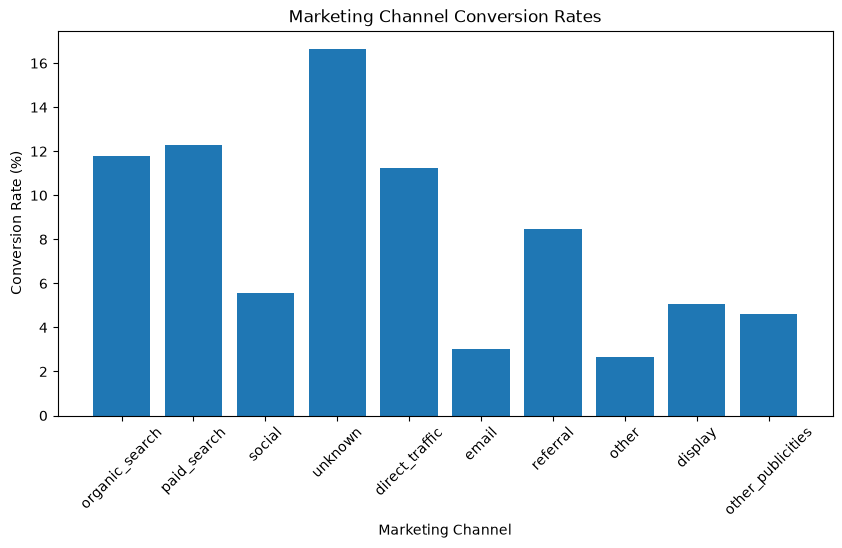

In [9]:
# Marketing Channel Conversion Chart

plt.figure(figsize=(10, 5))

plt.bar(channel_performance['origin'], channel_performance['conversion_rate_pct'])

plt.title('Marketing Channel Conversion Rates')
plt.xlabel('Marketing Channel')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=45)

plt.show()

In [10]:
# Loading data from SQL Server

items = pd.read_sql_query("SELECT order_id, seller_id, price FROM clean_order_items", connection)
orders = pd.read_sql_query("SELECT order_id, order_status, order_purchase_timestamp FROM clean_orders", connection)

# Connecting orders with items
sales = items.merge(orders, on='order_id')

# Identifying acquired sellers and their first closing date
acquired = deals.sort_values('won_date').drop_duplicates('seller_id')

# Keeping marketing-acquired sellers
sales = sales.merge(acquired[['seller_id', 'won_date']], on='seller_id')

# Keeping delivered sales after the seller's closing date
sales = sales[
    (sales['order_status'] == 'delivered') &
    (pd.to_datetime(sales['order_purchase_timestamp']) >= pd.to_datetime(sales['won_date']))
]

print("Qualifying Order Items:", len(sales))

C:\Users\ekans\AppData\Local\Temp\ipykernel_16880\2894663816.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  items = pd.read_sql_query("SELECT order_id, seller_id, price FROM clean_order_items", connection)
C:\Users\ekans\AppData\Local\Temp\ipykernel_16880\2894663816.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  orders = pd.read_sql_query("SELECT order_id, order_status, order_purchase_timestamp FROM clean_orders", connection)


Qualifying Order Items: 4984


In [11]:
# Calculating sales value for each seller

seller_sales = sales.groupby('seller_id')['price'].sum()

# Sort from highest to lowest
seller_sales = seller_sales.sort_values(ascending=False)

# Identify top 10% of active acquired sellers
top_10_count = round(len(seller_sales) * 0.10)

# Calculate their share of sales
top_10_sales = seller_sales.head(top_10_count).sum()
total_sales = seller_sales.sum()

revenue_share = (top_10_sales / total_sales) * 100

print("Active Acquired Sellers:", len(seller_sales))
print("Top 10% Seller Count:", top_10_count)
print("Top 10% Sales Share:", round(revenue_share, 2), "%")

Active Acquired Sellers: 376
Top 10% Seller Count: 38
Top 10% Sales Share: 64.82 %


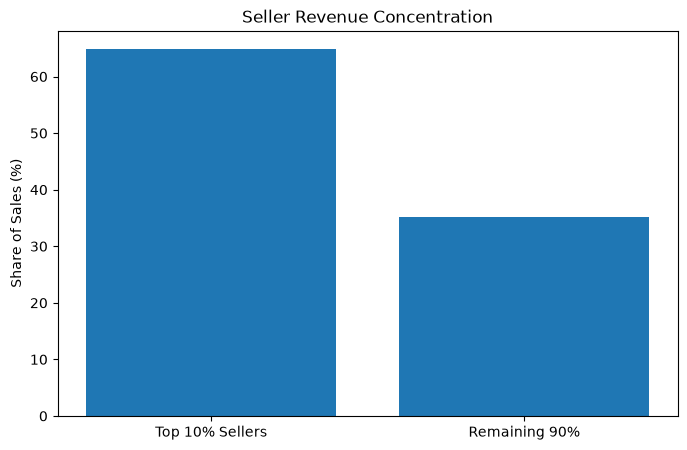

In [12]:
# Business question: How much sales value comes from the top 10% of acquired sellers?

# Seller Revenue Concentration

groups = ['Top 10% Sellers', 'Remaining 90%']
values = [revenue_share, 100 - revenue_share]

plt.figure(figsize=(8, 5))

plt.bar(groups, values)

plt.title('Seller Revenue Concentration')
plt.ylabel('Share of Sales (%)')

plt.show()

# Business insight:
# Approximately 10% of active acquired sellers generate 64.82% of qualifying sales,
# indicating high revenue concentration.

In [13]:
# Business question: Are newer leads converting more successfully than older leads?

# Lead Conversion Cohort Analysis

cohorts = leads.merge(
    deals[['mql_id', 'won_date']],
    on='mql_id',
    how='left'
)

# Convert dates
cohorts['first_contact_date'] = pd.to_datetime(cohorts['first_contact_date'])
cohorts['won_date'] = pd.to_datetime(cohorts['won_date'])

# Calculate days to close
cohorts['days_to_close'] = (
    cohorts['won_date'] - cohorts['first_contact_date']
).dt.days

# Identify deals closed within 30 days
cohorts['closed_30d'] = cohorts['days_to_close'].between(0, 30)

# Keep leads with at least 30 days of observable time
cutoff = cohorts['won_date'].max()
cohorts = cohorts[
    cohorts['first_contact_date'] <= cutoff - pd.Timedelta(days=30)
]

# Group by first contact month
cohorts['month'] = cohorts['first_contact_date'].dt.to_period('M')

result = cohorts.groupby('month').agg(
    total_leads=('mql_id', 'count'),
    closed_30d=('closed_30d', 'sum')
)

# Calculate 30-day conversion rate
result['conversion_rate'] = (
    result['closed_30d'] / result['total_leads'] * 100
).round(2)

display(result)

,total_leads,closed_30d,conversion_rate
month,,,
2017-06,4,0,0.00
2017-07,239,0,0.00
2017-08,386,0,0.00
2017-09,312,0,0.00
2017-10,416,0,0.00
2017-11,445,2,0.45
2017-12,200,1,0.50
2018-01,1141,96,8.41
2018-02,1028,101,9.82


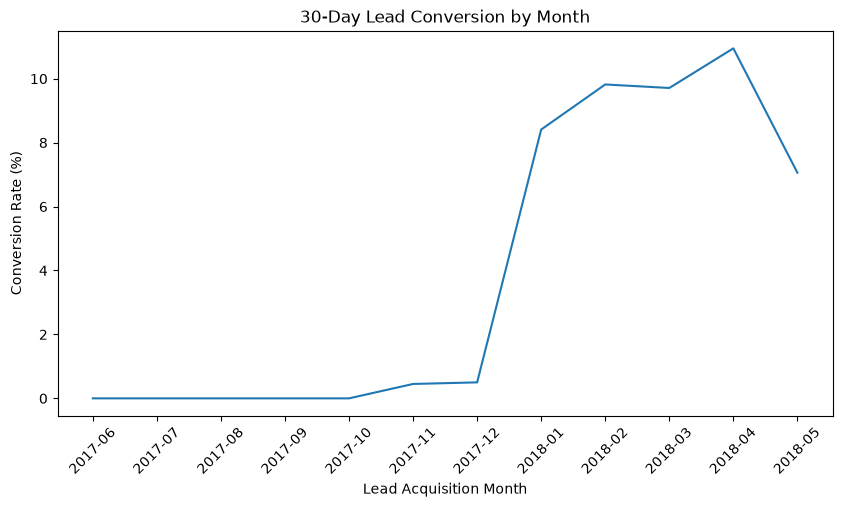

In [14]:
# Monthly 30-Day Conversion Trend

plt.figure(figsize=(10, 5))

plt.plot(result.index.astype(str), result['conversion_rate'])

plt.title('30-Day Lead Conversion by Month')
plt.xlabel('Lead Acquisition Month')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=45)

plt.show()

In [15]:
# Exporting Marketing Performance to Excel

channel_performance.to_csv(
    '../05_Excel/marketing_channel_validation.csv',
    index=False
)

print("File exported successfully!")

File exported successfully!


In [4]:
# Exporting all 9 cleaned SQL tables to CSV

tables = [
    'clean_marketing_leads',
    'clean_closed_deals',
    'clean_customers',
    'clean_orders',
    'clean_order_items',
    'clean_payments',
    'clean_products',
    'clean_sellers',
    'clean_category_translation'
]

for table in tables:
    df = pd.read_sql_query(f"SELECT * FROM {table}", connection)
    df.to_csv(f"../02_Cleaned_Data/{table}.csv", index=False)
    print(table, "- Exported")

C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)


clean_marketing_leads - Exported
clean_closed_deals - Exported


C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)
C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)


clean_customers - Exported


C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)


...

C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)


clean_payments - Exported


C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)


clean_products - Exported
clean_sellers - Exported
clean_category_translation - Exported


C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)
C:\Users\ekans\AppData\Local\Temp\ipykernel_2736\2800347637.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(f"SELECT * FROM {table}", connection)
